# Figure 8-5 — temperature

The study model scales resistors at 50 ppm/°C and capacitors at 30 ppm/°C,
referenced to 25 °C. The grid is −40 °C to 125 °C. The transient cache uses
the positive TCR and TCC signs. ngspice and LTspice see those scaled
passives through the ideal voltage-controlled source, which has no
semiconductor temperature law of its own.

A second analytical sweep flips the signs of TCR and TCC. Bias-current
growth, where it is plotted, is a smooth study model, exp(0.062·ΔT), not a
datasheet curve. It is about 1× at 25 °C and about 500× at 125 °C.

Created with Grok Build.


In [1]:
import sys

import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import io
from pathlib import Path
from IPython.display import display, Image

def _show(*args, **kwargs):
    buf = io.BytesIO()
    fig = plt.gcf()
    fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    plt.close("all")
    display(Image(data=buf.getvalue()))

plt.show = _show

def _find_project_root():
    start = Path.cwd().resolve()
    named = Path("Sections/Electronics/Analog_and_Digital/OPA365_Fig85")
    candidates = [start, *start.parents, start / named]
    if start.name == "notebooks":
        candidates.insert(0, start.parent)
    for cand in candidates:
        if (cand / "mfb_design" / "__init__.py").is_file():
            return cand
    raise FileNotFoundError("mfb_design package was not found")

ROOT = _find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [2]:
from mfb_design.params import CircuitParams, ToleranceSpec

p = CircuitParams(
    R1=549.0,
    R2=1.24e3,
    R3=549.0,
    C1=1.0e-9,
    C2=150.0e-12,
    r_tol=ToleranceSpec(0.001),
    c_tol=ToleranceSpec(0.01),
)
SPICE_WORKERS = 4
N_MC_AC = 2000
N_MC_TRAN = 500
MC_SEED = 42
print(
    f"R1={p.R1:g} ohm  R2={p.R2:g} ohm  R3={p.R3:g} ohm  "
    f"C1={p.C1:g} F  C2={p.C2:g} F"
)
print(
    f"supplies {p.op.v_pos:g} V / {p.op.v_neg:g} V, "
    f"tone {p.op.f_passband_hz:g} Hz, {p.op.v_in_peak:g} V peak"
)
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


R1=549 ohm  R2=1240 ohm  R3=549 ohm  C1=1e-09 F  C2=1.5e-10 F
supplies 2.5 V / -2.5 V, tone 250000 Hz, 1 V peak


In [3]:
from mfb_design.temperature import spice_temp_sweep, sweep_analytical
from mfb_design.transient import load_or_run_temperature

temp = load_or_run_temperature(
    p,
    root=ROOT,
    cache_csv=ROOT / "results" / "temperature_tran.csv",
    workers=SPICE_WORKERS,
)
if not bool(temp["ng_ok"].all()) or temp["lt_gain"].isna().any():
    raise RuntimeError("temperature cache is incomplete")
display(temp)
ng_err = float((temp["ng_gain"] - temp["an_gain"]).abs().max())
lt_err = float((temp["lt_gain"] - temp["an_gain"]).abs().max())
print(f"max |ngspice − analytical| gain = {ng_err:.3e}")
print(f"max |LTspice − analytical| gain = {lt_err:.3e}")
if ng_err > 1e-3 or lt_err > 1e-3:
    raise RuntimeError("a solver disagrees with the analytical temperature gain")


max |ngspice − analytical| gain = 4.279e-05
max |LTspice − analytical| gain = 1.015e-04


temp_c,an_gain,an_phase_deg,an_vin_amp,an_vout_amp,an_vin_dc,an_vout_dc,ng_gain,ng_phase_deg,ng_ok,lt_gain,lt_phase_deg
-40,0.967841,136.595,1,0.967841,0,0,0.9678,136.579,True,0.9678,136.59
-30,0.967746,136.557,1,0.967746,0,0,0.967705,136.541,True,0.9677,136.56
-20,0.967652,136.518,1,0.967652,0,0,0.96761,136.503,True,0.9676,136.52
-10,0.967557,136.48,1,0.967557,0,0,0.967515,136.465,True,0.9675,136.48
0,0.967461,136.442,1,0.967461,0,0,0.96742,136.426,True,0.9674,136.44
10,0.967366,136.404,1,0.967366,0,0,0.967325,136.388,True,0.9673,136.4
20,0.96727,136.365,1,0.96727,0,0,0.967229,136.35,True,0.9672,136.36
25,0.967223,136.346,1,0.967223,0,0,0.967181,136.331,True,0.9672,136.35
30,0.967175,136.327,1,0.967175,0,0,0.967133,136.311,True,0.9671,136.33
40,0.967079,136.289,1,0.967079,0,0,0.967037,136.273,True,0.967,136.29


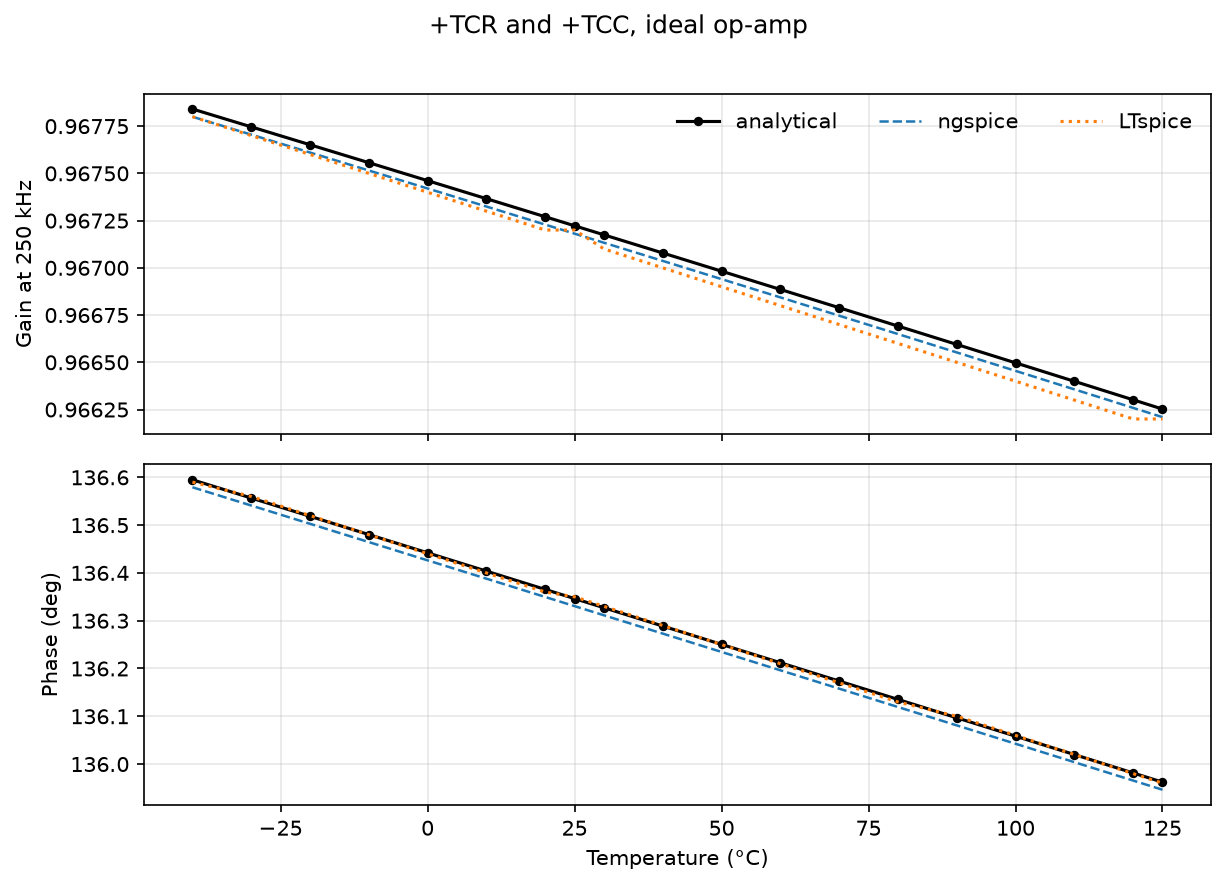

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(8.2, 5.8), sharex=True)
axes[0].plot(temp["temp_c"], temp["an_gain"], "k-o", ms=3.5, lw=1.5, label="analytical")
axes[0].plot(temp["temp_c"], temp["ng_gain"], "C0--", lw=1.2, label="ngspice")
axes[0].plot(temp["temp_c"], temp["lt_gain"], "C1:", lw=1.5, label="LTspice")
axes[0].set_ylabel("Gain at 250 kHz")
axes[0].legend(frameon=False, ncol=3)
axes[0].grid(True, alpha=0.3)
axes[1].plot(temp["temp_c"], temp["an_phase_deg"], "k-o", ms=3.5, lw=1.5)
axes[1].plot(temp["temp_c"], temp["ng_phase_deg"], "C0--", lw=1.2)
axes[1].plot(temp["temp_c"], temp["lt_phase_deg"], "C1:", lw=1.5)
axes[1].set_xlabel("Temperature (°C)")
axes[1].set_ylabel("Phase (deg)")
axes[1].grid(True, alpha=0.3)
fig.suptitle("+TCR and +TCC, ideal op-amp", y=1.01)
fig.tight_layout()
fig.savefig(FIG / "06_temperature_tran.png", dpi=150)
plt.show()


max |ngspice − analytical| fc = 1.619e+02 Hz


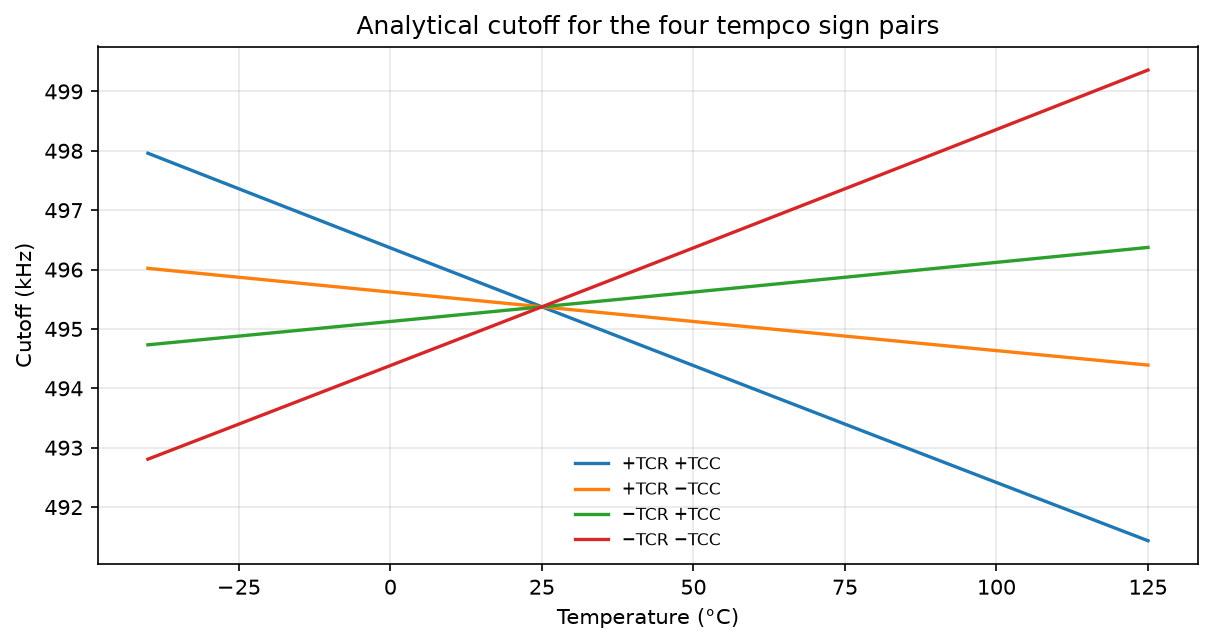

temp_c,fc_hz,fc_spice_hz,passband_gain_spice,fc_delta_Hz
-40,497959,497797,0.999998,-161.901
-30,497560,497409,0.999998,-150.283
-20,497161,497023,0.999998,-138.104
-10,496763,496637,0.999998,-125.371
0,496365,496253,0.999998,-112.087
10,495968,495869,0.999998,-98.2565
20,495571,495487,0.999998,-83.886
25,495373,495296,0.999998,-76.499
30,495175,495106,0.999998,-68.9793
40,494779,494725,0.999998,-53.5408


In [5]:
fig, ax = plt.subplots(figsize=(8.2, 4.4))
pairs = ((1.0, 1.0, "+TCR +TCC"), (1.0, -1.0, "+TCR −TCC"),
         (-1.0, 1.0, "−TCR +TCC"), (-1.0, -1.0, "−TCR −TCC"))
an_fc = None
for tcr, tcc, label in pairs:
    fr = sweep_analytical(
        p, tcr_sign=tcr, tcc_sign=tcc, use_ib_max_at_temp=False,
    ).frame
    ax.plot(fr["temp_c"], fr["fc_hz"] / 1e3, lw=1.6, label=label)
    if tcr > 0 and tcc > 0:
        an_fc = fr
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Cutoff (kHz)")
ax.set_title("Analytical cutoff for the four tempco sign pairs")
ax.grid(True, alpha=0.3)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "06_fc_sign_pairs.png", dpi=150)
plt.show()

ng = spice_temp_sweep(
    p,
    workdir=ROOT / "results" / "ngspice" / "nb06_ac_temp",
    root=ROOT,
    opamp_model="ideal",
    tcr_sign=1.0,
    tcc_sign=1.0,
)
cmp = an_fc[["temp_c", "fc_hz"]].merge(ng.frame, on="temp_c")
cmp["fc_delta_Hz"] = cmp["fc_spice_hz"] - cmp["fc_hz"]
display(cmp)
print(f"max |ngspice − analytical| fc = {cmp['fc_delta_Hz'].abs().max():.3e} Hz")


DC error at 25 °C is 0.03 µV. At 125 °C it is -185.0 µV.


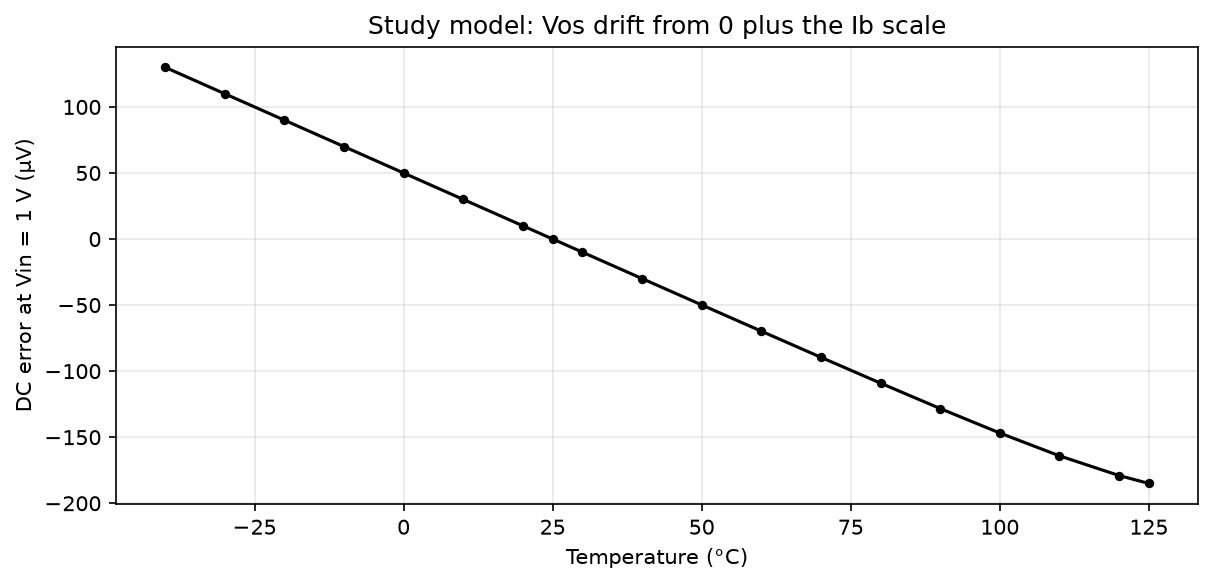

In [6]:
dc = sweep_analytical(p, tcr_sign=1.0, tcc_sign=1.0, vos_25=0.0, use_ib_max_at_temp=True).frame
fig, ax = plt.subplots(figsize=(8.2, 4.0))
ax.plot(dc["temp_c"], dc["dc_error"] * 1e6, "k-o", ms=3.5, lw=1.5)
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("DC error at Vin = 1 V (µV)")
ax.set_title("Study model: Vos drift from 0 plus the Ib scale")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "06_dc_error.png", dpi=150)
plt.show()
print(
    f"DC error at 25 °C is {float(dc.loc[dc.temp_c==25, 'dc_error'].iloc[0])*1e6:.2f} µV. "
    f"At {dc.temp_c.max():.0f} °C it is {float(dc.iloc[-1]['dc_error'])*1e6:.1f} µV."
)
